# Predicting Sales Prices

 ## Dataset Attributes

 The dataset contains information about houses in Ames, Iowa. The data was collected by the Ames City Assessor’s Office describing 2930 property sales which occurred in Ames, Iowa between 2006 and 2010. The dataset, containing 81 variables, was compiled and published by De Cock in 2011.

 Some of the variables contained in the original dataset have been removed from the the dataset provided to you.
 The dataset provided to you contains the following variables:
* **Year_Built:** year that the house was originally constructed
* **Year_Remod_Add:** year that the house was last remodelled
* **Total_Bsmt_SF:** total size of basement area in square feet
* **First_Flr_SF:** size of the first floor in square feet
* **Second_Flr_SF:** size of the second floor in square feet
* **Gr_Liv_Area:** size of above grade, ground living area in square feet
* **Full_Bath:** number of full above grade bathrooms in the house
* **Half_Bath:** number of half above grade bathrooms in the house
* **Bedroom_AbvGr:** number of above grade bedrooms (does not include basement bedrooms)
* **Kitchen_AbvGr:** number of above grade kitchens
* **TotRms_AbvGrd:** total number of above grade rooms (does not include bathrooms)
* **Fireplaces:** number of fireplaces in the house
* **Garage_Area:** size of garage in square feet
* **Sale_Price:** sale price of the house in dollars


*De Cock, D. (2011). "Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester
Regression Project," Journal of Statistics Education, Volume 19, Number 3.*

- https://ww2.amstat.org/publications/jse/v19n3/decock/DataDocumentation.txt
- http://ww2.amstat.org/publications/jse/v19n3/decock.pdf


 ## Objective

 The goal of this task is to analyse the relationship between these variables and build a multiple linear regression model to predict the sales prices based on the 'Gr_Liv_Area' and 'Garage_Area` variables.


In [1]:
# Import libraries
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score, mean_squared_error 


%matplotlib inline


In [111]:
# Read in the data set
ames_data = pd.read_csv('ames.csv')
ames_data.head()


,Year_Built,Year_Remod_Add,Total_Bsmt_SF,First_Flr_SF,Second_Flr_SF,Gr_Liv_Area,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,TotRms_AbvGrd,Fireplaces,Garage_Area,Sale_Price
0,1960,1960,1080,1656,0,1656,1,0,3,1,7,2,528,215000
1,1961,1961,882,896,0,896,1,0,2,1,5,0,730,105000
2,1958,1958,1329,1329,0,1329,1,1,3,1,6,0,312,172000
3,1968,1968,2110,2110,0,2110,2,1,3,1,8,2,522,244000
4,1997,1998,928,928,701,1629,2,1,3,1,6,1,482,189900


## Clean and pre-process the data if neccessary

In [ ]:
# no missing values and dtype is int64
missing_values_count = ames_data.isnull().sum()
missing_values_count[:]



Year_Built        0
Year_Remod_Add    0
Total_Bsmt_SF     0
First_Flr_SF      0
Second_Flr_SF     0
Gr_Liv_Area       0
Full_Bath         0
Half_Bath         0
Bedroom_AbvGr     0
Kitchen_AbvGr     0
TotRms_AbvGrd     0
Fireplaces        0
Garage_Area       0
Sale_Price        0
dtype: int64

In [ ]:
# This gives a full in-depth info about our columns and 
# the data types of each column and whether they are correct or not. 
ames_data.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Year_Built      2930 non-null   int64
 1   Year_Remod_Add  2930 non-null   int64
 2   Total_Bsmt_SF   2930 non-null   int64
 3   First_Flr_SF    2930 non-null   int64
 4   Second_Flr_SF   2930 non-null   int64
 5   Gr_Liv_Area     2930 non-null   int64
 6   Full_Bath       2930 non-null   int64
 7   Half_Bath       2930 non-null   int64
 8   Bedroom_AbvGr   2930 non-null   int64
 9   Kitchen_AbvGr   2930 non-null   int64
 10  TotRms_AbvGrd   2930 non-null   int64
 11  Fireplaces      2930 non-null   int64
 12  Garage_Area     2930 non-null   int64
 13  Sale_Price      2930 non-null   int64
dtypes: int64(14)
memory usage: 320.6 KB


Now we rename our columns for easier calling within the code. Since we are only measure Gr_Living_Area and Garage_Size against Sales_Price, we will rename these columns.  

In [114]:
# Create new Dataframe for our specified analyses
ames_subset_df = pd.DataFrame({
    'groundfloor' : ames_data['Gr_Liv_Area'],
    'garage' : ames_data['Garage_Area'],
    'price' : ames_data['Sale_Price']
})


## Explore the data with visualisations such as histograms and correlation matrices


In [115]:
# Explore the data with visualisations such as histograms and correlation matrices

correlation_matrix = ames_subset_df[['groundfloor', 'garage', 'price']].corr()

print(correlation_matrix)


             groundfloor    garage     price
groundfloor     1.000000  0.483971  0.706780
garage          0.483971  1.000000  0.640138
price           0.706780  0.640138  1.000000


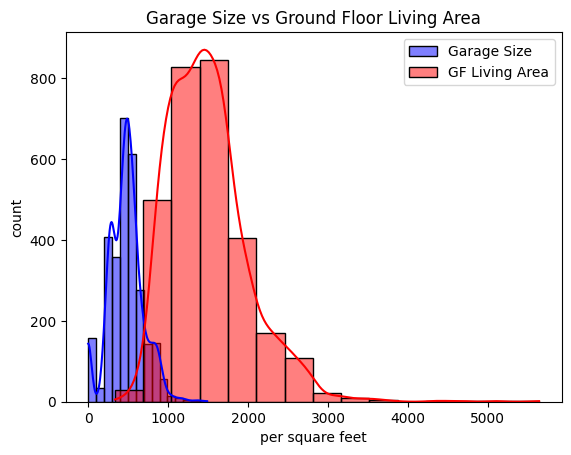

In [116]:
sns.histplot(data=ames_subset_df['garage'], color='blue', label='Garage Size', bins=15, kde=True)
sns.histplot(data=ames_subset_df['groundfloor'], color='red', label='GF Living Area', bins=15, kde=True)

plt.title("Garage Size vs Ground Floor Living Area")
plt.xlabel('per square feet')
plt.ylabel('count')
plt.legend()
plt.show()
plt.close()


The histogram suggests that the Garage Size is normally distributed, this means that there are many houses that do not have very small or large garage sizes, all data is balanced. The ground floor living area is rightly-skewed which means that most houses have average size groundfloor living area sizes, but there are few that skew the data to the right where these small portion of houses may be bigger and have a bigger groundfloor living area size. 

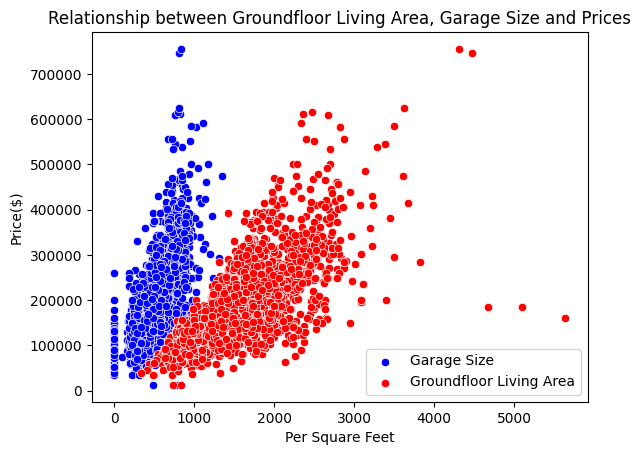

In [117]:
# Multi-plot grid to see the relationship between groundfloor and price
# garage size and price 

plt.figure()
sns.scatterplot(data=ames_subset_df, x='garage', y='price', label='Garage Size', color='blue')
sns.scatterplot(data=ames_subset_df, x='groundfloor', y='price', label='Groundfloor Living Area', color='red')
plt.title("Relationship between Groundfloor Living Area, Garage Size and Prices")
plt.xlabel('Per Square Feet')
plt.ylabel('Price($)')
plt.legend()
plt.show()
plt.close()

This lineplot illustrates that there is a normal distribution of garage size which entails that most houses in Ames, Iowa have average garage sizes; fewer houses have very small or very large garages. It also shows that as garage sizes increases so does house prices. However, it is not that much of a strong correlation, as above the correlation matrix is 0.64. Thus, garage size does matter, but is not the main driver of the price. In terms of groundfloor living area, the data is rightly skewed, suggesting that most houses have smaller-medium sized living areas. There are also some large houses that have a large living area. The graph also shows us that there is a strong influence on predicting prices. As groundfloor living area increases so does the price with a strong correlation matrix of 0.71. Thus, the size of the groundfloor living area is a much stronger indicator of house prices than garage sizes. As the data is rightly skewed, this may affect our linear regression so a log transformation can be explored to fix the skewness and not affect our regression. 

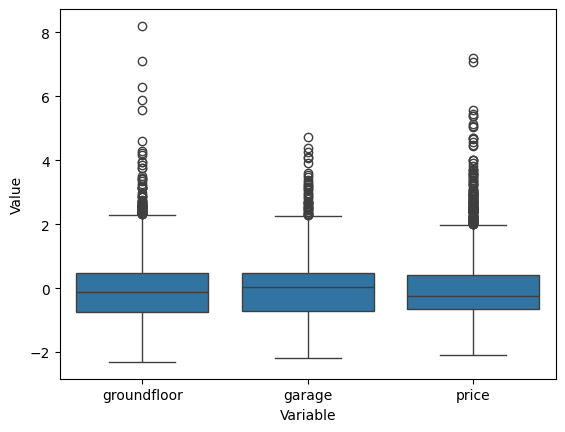

In [118]:
# Scaling data to find any outliers within our IVs and our DV
scaler=StandardScaler()
scaled_data = scaler.fit_transform(ames_subset_df)
scaled_data_df = pd.DataFrame(scaled_data, 
                              columns=['groundfloor',
                                       'garage',
                                       'price'])

# Melt and Plot original and scaled data to compare 
melted_df = pd.melt(scaled_data_df, var_name='Variable', value_name='Value')
sns.boxplot(melted_df, x='Variable', y='Value')
plt.show()


Seems that there are many outliers in both IVs and DV. Suggesting there needs to be some more data cleaning, however it is not necessary as the garage area column has data values of 0 which may be seen as an outlier, but can be valid data points, which could simply mean that the house does not have garages. Therefore, there was no reason to remove these 0 value records. In order to even out the outliers we can as previously mentioned, carry out a log transformation. 

## Explore relationships between the independent and dependent variables (Simple Linear Regression)


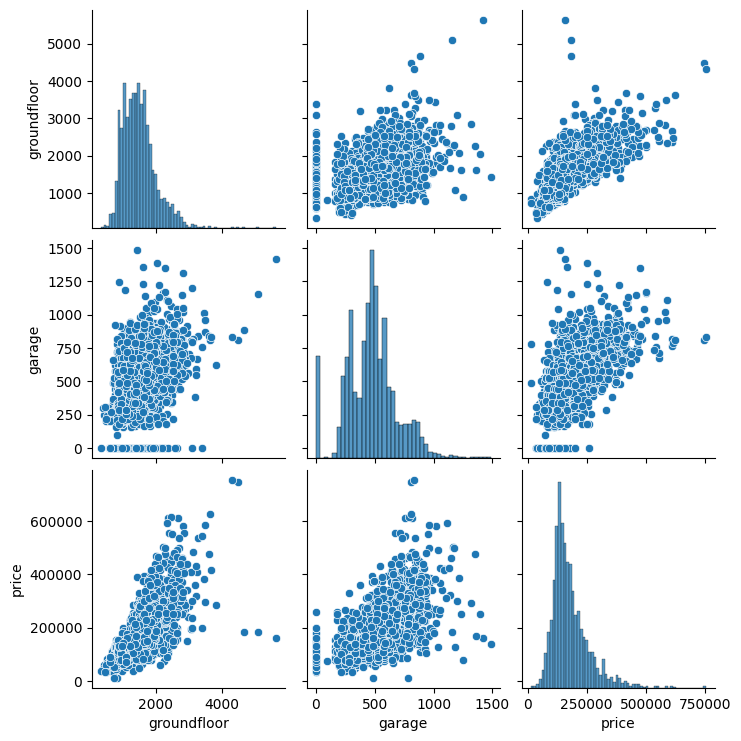

In [119]:
# Pairplot to visualise relationship between IVs and DV
sns.pairplot(ames_subset_df)
plt.show()

**Garage VS Price**

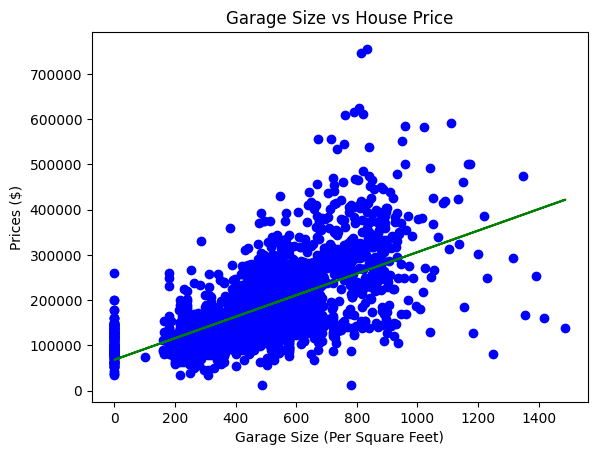

In [120]:
# Selected and reshaped data 
x = ames_subset_df.iloc[:, 1].values
y = ames_subset_df.iloc[:, 2].values
x=x.reshape(-1,1)
y=y.reshape(-1,1)

# Creating an empty linear regression model 
garage_model = LinearRegression()

# Fit the data into the model
garage_model.fit(x, y)

# Use model to make a prediction 
y_pred = garage_model.predict(x)

# Plot model and data
plt.scatter(x,y,color = 'b')
plt.plot(x, garage_model.predict(x),color ='g')
plt.title('Garage Size vs House Price')
plt.xlabel("Garage Size (Per Square Feet)")
plt.ylabel("Prices ($)")
plt.show()


In [121]:
print('Coefficeints: \n', garage_model.coef_)

Coefficeints: 
 [[237.64672033]]


The coefficient result suggests that for every additional sqaure feet of the garage size there will be an increase of $237.65 per square feet.

**Groundfloor Living Area vs Prices**

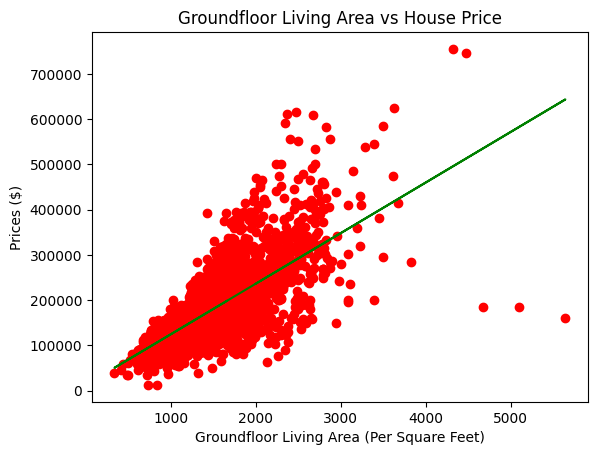

In [122]:
# Selected and reshaped data 
x = ames_subset_df.iloc[:, 0].values
y = ames_subset_df.iloc[:, 2].values
x=x.reshape(-1,1)
y=y.reshape(-1,1)

# Creating an empty linear regression model 
gf_area_model = LinearRegression()

# Fit the data into the model
gf_area_model.fit(x, y)

# Use model to make a prediction 
y_pred = gf_area_model.predict(x)

# Plot model and data
plt.scatter(x,y,color = 'r')
plt.plot(x, gf_area_model.predict(x),color ='g')
plt.title('Groundfloor Living Area vs House Price')
plt.xlabel("Groundfloor Living Area (Per Square Feet)")
plt.ylabel("Prices ($)")
plt.show()

In [123]:
print("Coefficeint:", gf_area_model.coef_)

Coefficeint: [[111.69400086]]


The coefficient result suggests that for every additional sqaure feet of the groundfloor living area there will be an increase of $237.65 per square feet.

## Multiple Linear Regression

In [124]:
# Split the independent variables from the dependent variable
X = ames_subset_df[['garage','groundfloor']].values
X


array([[ 528, 1656],
       [ 730,  896],
       [ 312, 1329],
       ...,
       [   0,  970],
       [ 418, 1389],
       [ 650, 2000]], shape=(2930, 2))

In [125]:
y = ames_subset_df[['price']].values 
y

array([[215000],
       [105000],
       [172000],
       ...,
       [132000],
       [170000],
       [188000]], shape=(2930, 1))

In [126]:
# Create a training and test set with a 75:25 split ratio
rseed = 23 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=rseed)

print('Training data:', X_train.shape, y_train.shape)
print('Test data:', X_test.shape, y_test.shape)


Training data: (2197, 2) (2197, 1)
Test data: (733, 2) (733, 1)


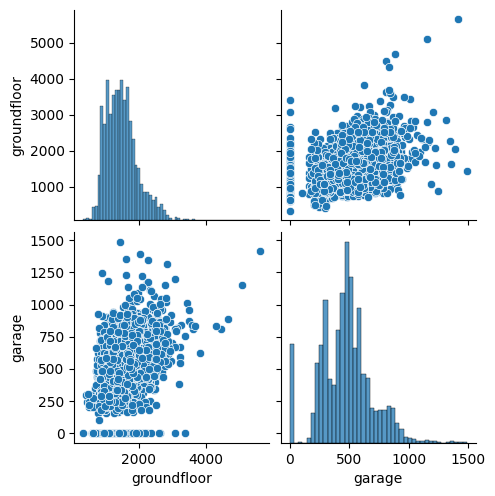

In [127]:
sns.pairplot(ames_subset_df[['groundfloor', 'garage']])


groundfloor follows a gaussian distribution, whereas garage_sizes does not and is rightly skewed. This won't need any scaling as the data is all measured in square feet so have the same measurements/scale. Also, it's not necessary but to get a more accurate and reliable multiple linear regression a log transformation can be performed to remove the rightly skewed data.

In [128]:
# Build a multiple linear regression model using 'Gr_Liv_Area' and 'Garage_Area'

# Fit model on training and test data
lm = LinearRegression()
model = lm.fit(X_train, y_train)
predictions = lm.predict(X_test)

# Create line coordinates 
X_line = np.empty(X_test.shape)
for i in range(X_test.shape[1]):
    X_line[:, i] = np.linspace(np.min(X_test[:, i]), np.max(X_test[:, i]), num=X_test.shape[0])
y_line=lm.predict(X_line)



In [129]:
# Print the model intercept and coefficients

print("Intercepts: \n", lm.intercept_)
print("Coefficeints: \n", lm.coef_)


Intercepts: 
 [-15408.30057694]
Coefficeints: 
 [[143.47756103  86.00612276]]


In [130]:
# Generate predictions for the test set
print("Groundfloor living area price predictions: ", predictions[0:5])
print("Garage size prices:", predictions[1:5])

Groundfloor living area price predictions:  [[105306.53797291]
 [159127.88786951]
 [167769.09690901]
 [ 58900.98948901]
 [364961.45947664]]
Garage size prices: [[159127.88786951]
 [167769.09690901]
 [ 58900.98948901]
 [364961.45947664]]


The intercepts and coefficents below tell us that when the garage and groundfloor living area size is 0, the price of the house will be -15,408. Whilst this is practically meaningless in the real world, mathematically this is what it would be. In terms of the coefficients, it tells us the price for every additional square foot of groundfloor living areas and garage sizes. Groundfloor living area is predicted to increase approx. $143.48 and garage sizes predicted to increase approx. $86.01. 

In [131]:
# Evaluate the model
rmse = np.sqrt(mean_squared_error(y_test, predictions))
print("Rmse:", rmse)

r2 = r2_score(y_test, predictions)
print("R2:", r2)


Rmse: 53246.98852788171
R2: 0.5696221653633046


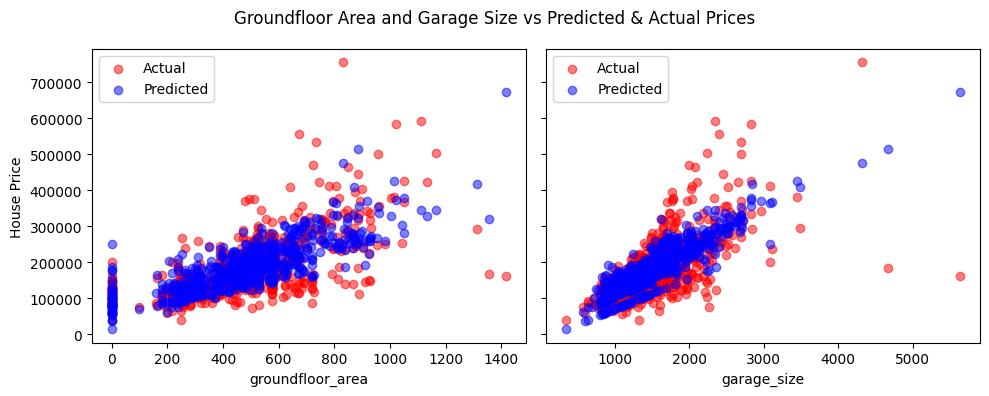

In [133]:
fig, ax = plt.subplots(1, X_test.shape[1], sharey=True, figsize=(10, 4))
fig.suptitle("Groundfloor Area and Garage Size vs Predicted & Actual Prices")

feature_names = ['groundfloor_area', 'garage_size']

for i in range(X_test.shape[1]):
    ax[i].scatter(X_test[:, i], y_test, color='red', label='Actual', alpha=0.5)
    ax[i].scatter(X_test[:, i], predictions, color='blue', label='Predicted', alpha=0.5)
    ax[i].set_xlabel(feature_names[i])
    ax[i].legend()

ax[0].set_ylabel("House Price")
plt.tight_layout()
plt.show()


The residual plot illustrates that there are outliers and that there is an increase in variance as the price increases. This may be due to the rightly skewed data where the large groundfloor living areas are outliers and affecting the data. 

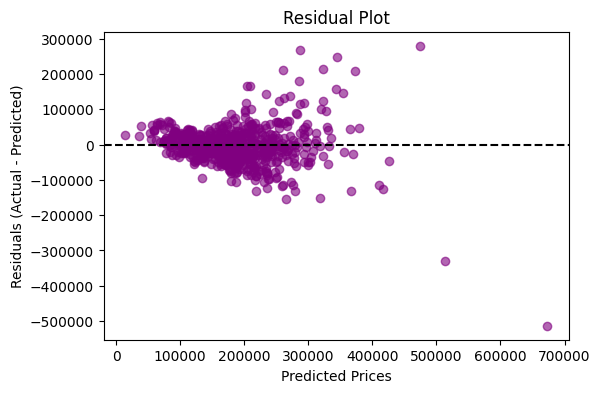

In [132]:
import matplotlib.pyplot as plt

# Residuals
residuals = y_test - predictions

plt.figure(figsize=(6,4))
plt.scatter(predictions, residuals, color='purple', alpha=0.6)
plt.axhline(y=0, color='black', linestyle='--')
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()


Now that the residual plot has shown variance as the price increases it could have a problem when predicted high value houses. Therefore to lower the variance we will log transform all the IVs and DV to make it all on the same normality. 

**Interpret coefficients in the context of the prediction:**


The coefficient for Gr_Liv_SF, Garage_Area are 143.47756103 and 86.00612276. These results tell use that for every additional 1 sqaure foot of groundfloor living area, the model predicts that the house price increases by approximately $143.48, this is only assuming that the groundfloor are remains the same. In terms of garage_size, for every additional 1 square foot of garage area, the model predicts the house price increases by approaxiamtely $86.01, assuming that the garage size remains the same. In relation to the intercept, although it gives us a negative value of -15,408.03 and that it is basically meaningless in the real-world, because a house cannot have a 0 size garage and groundfloor living area so when it is 0 for these features then the price of the house will be -$15,408.03. 


**Summarise findings**

In summary, the multiple linear regression between groundfloor living area and garage size were positively associated with house prices. Specifically, each additional square foot of groundfloor living area increased the house price by $143.48, and each additional square foot of garage increased the house price by $86.01, holidng that the other variables were constant. This model provides a clear linear relationship between both property size features and price. 